In [1]:
from openpile.construct import Pile, CircularPileSection

p = Pile(
    name = "",
    sections = [
        CircularPileSection(
            top = 0,
            bottom = -40,
            material = "Steel",
            diameter = 2,
            thickness = 0.05,
        )
    ]
)
p

Pile(name='', sections=[CircularPileSection(top=0.0, bottom=-40.0, material=PileMaterial(name='Steel', uw=78.0, E=210000000.0, nu=0.3), diameter=2.0, thickness=0.05)])

In [2]:
from openpile.weap import WeapMesh

w = WeapMesh.from_pile( p, 1.0)

In [3]:
from openpile.weap import run_explicit_weap_analysis_with_top_excitation

import numpy as np

# hammer parameters
m_ram, v_ram = 1000.0, 1.0          # 5 t ram, 3 m/s impact
k_c = 200e6                          # cap block stiffness
T  = np.pi * np.sqrt(m_ram / k_c)    # pulse duration


def blow_force(t):
    if t < 0 or t > T:
        return 0.0
    return -v_ram * np.sqrt(k_c * m_ram) * np.sin(np.sqrt(k_c / m_ram) * t)

input_acc = np.array([[t, blow_force(t) / m_ram] for t in np.linspace(0, 2*T, 1000)])

t, u, v, a = run_explicit_weap_analysis_with_top_excitation(
    w,
    input_acc,
    0.1
)

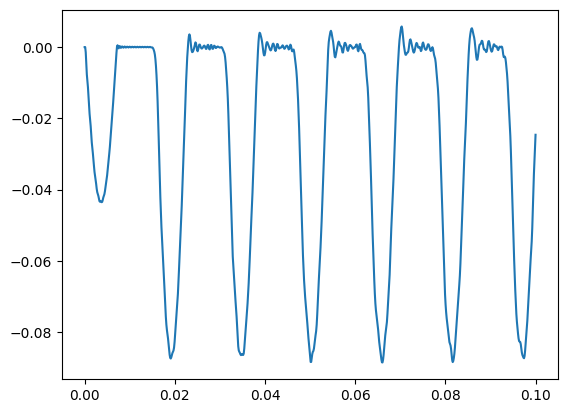

In [12]:
import matplotlib.pyplot as plt

#plt.plot(t, u, label="Displacement (m)")
plt.plot(t, v, label="Velocity (m/s)")
#plt.plot(t, a, label="Acceleration (m/s²)")
# input_acc = np.array([[t, blow_force(t) / m_ram] for t in np.linspace(0, 2*T, 1000)])
# plt.plot(input_acc[:,0], input_acc[:,1], label="Input Acceleration (m/s²)")

In [5]:
T

0.007024814731040727